<p style="text-align:right">Polytech Nantes</p>

# Visualisations avec Pandas

## Objectif & Plan

La bibliothèque [pandas](http://pandas.pydata.org/) est connue pour faciliter la manipulation de données, mais elle offre aussi des méthodes pour l'analyse statistique et la visualisation de données. L'objectif de cette séance est d'introduire les principales méthodes pour ces tâches.

A noter : [pandas](http://pandas.pydata.org/) utilise nativement [matplotlib](https://matplotlib.org) pour construire ses graphiques. [matplotlib](https://matplotlib.org) est la bibliothèque Python de référence pour la visualisation de données. Pour certains graphiques avancés qui ne sont pas proposés dans [pandas](http://pandas.pydata.org/), il faudra utiliser directement [matplotlib](https://matplotlib.org).

Dans ce notebook, nous réalisons les actions suivantes:
1. chargement des données
2. visualisation via Pandas

### Chargement des données

Le plus simple, pour charger vos données, est tout simplement d'utiliser notre classe `Loader` que nous présenterons plus tard :

In [1]:

%run -i "BaseLoader.ipynb"

loader = Loader(debug=False)

loader.loadSource(Loader.COINCODEX)

btc = loader.get(Loader.COINCODEX, Loader.BTC)

btc.head()

,High,Low,Open,Close,Volume,Marketcap
Date,,,,,,
2010-07-17,0.0500,0.0500,0.0500,0.0500,0.0,170803.152488
2010-07-18,0.0858,0.0858,0.0858,0.0858,0.0,294746.595000
2010-07-19,0.0808,0.0808,0.0808,0.0808,0.0,277570.220000
2010-07-20,0.0747,0.0747,0.0747,0.0747,0.0,256710.178548
2010-07-21,0.0792,0.0792,0.0792,0.0792,0.0,274308.375000


Un peu de configuration pour afficher nos futurs figures :
- import des bibliothèques
- paramètre pour définir la largeur / hauteur des figures
- seaborn est une autre bibliothèque pour afficher des figures, censée être plus simple que matplot (mais aussi basé sur cette dernière)

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams['figure.figsize'] = [15, 8] # paramètre pour les figures


**Questions** : 
1. vérifier que votre DataFrame `ada` est bien chargé
2. pour chaque dataFrame, vérifier le nombre de lignes et les types des variables à l'aide des attributs `shape` et `dtypes`. Dans [pandas](http://pandas.pydata.org/), les Objects désignent des chaînes de caractères.
3. les index sont bien les dates ? 

In [23]:
ada = loader.get(Loader.COINCODEX, Loader.ADA)
ada.head()

ada.dtypes
ada.shape
btc.shape

# La taille de ADA est bien respectée et les indexs sont bien les dates.

(5589, 6)

### Visualisation via Pandas

Voici un exemple simple pour afficher le cours du btc:

<Axes: xlabel='Date'>

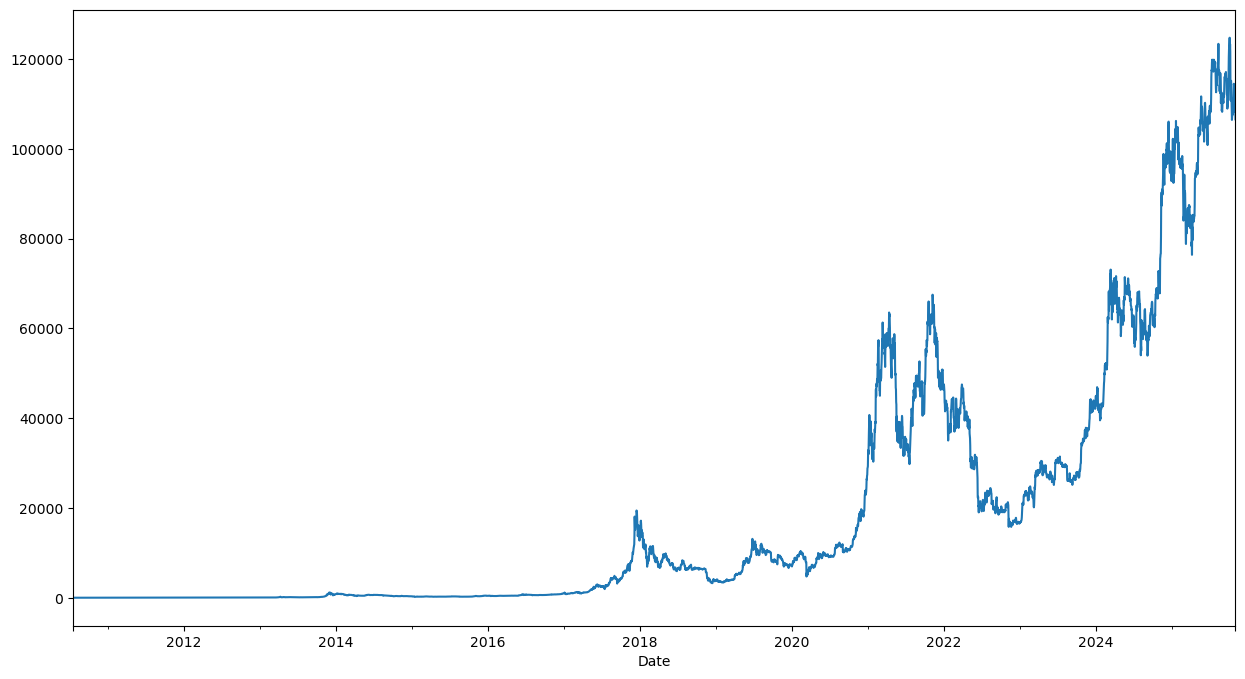

In [7]:
btc.loc[:, "Close"].plot()


Pour obtenir la distribution des données :

<Axes: >

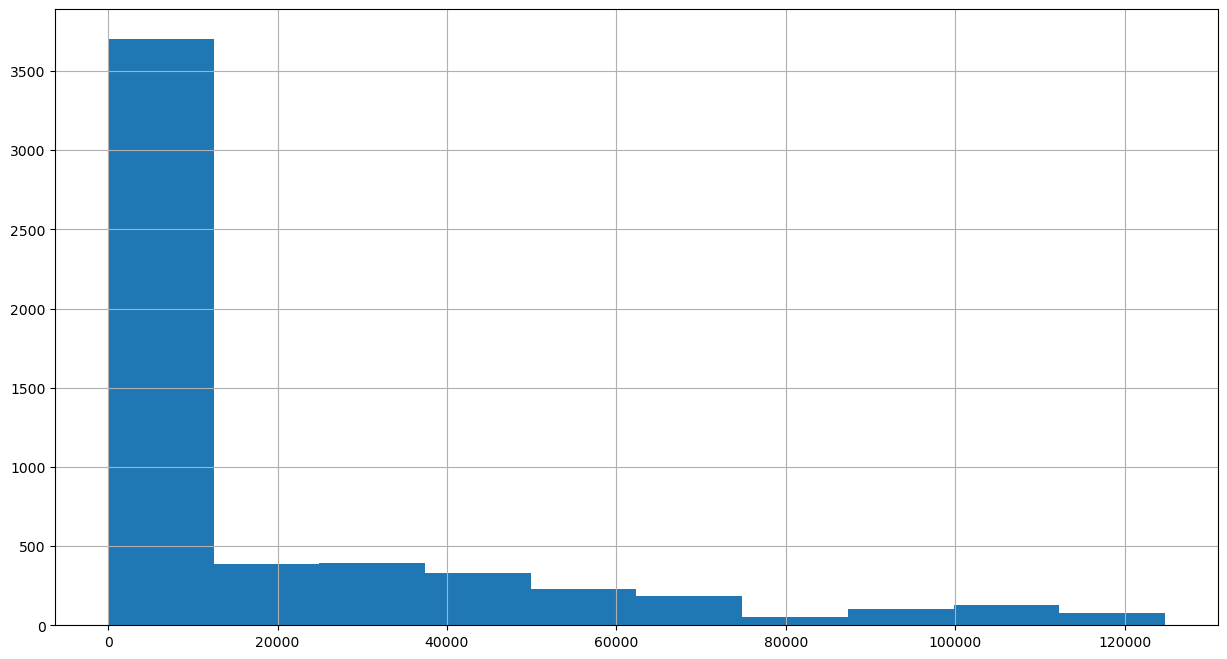

In [8]:
btc.loc[:, "Close"].hist(bins=10)

**Questions**:
1. étudier la fonction [`hist`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.hist.html)
2. créer la figure précédente en modifiant la couleur des barres. Une recherche Google sera néecessaire, des arguments n'apparaissant pas dans la documentation (Google `pandas hist color bar` m'a permis de trouver une réponse StackOverflow)
3. augmenter le nombre d'intervalles jusqu'à 500 ou 1000 par exemple (vous voyez des détails plus précis mais perdez l'illusion d'une distribution continue des notes). Réduiser l'intervalle, par exemple à 10. Est ce que chaque schéma fourni la même information ?

<Axes: >

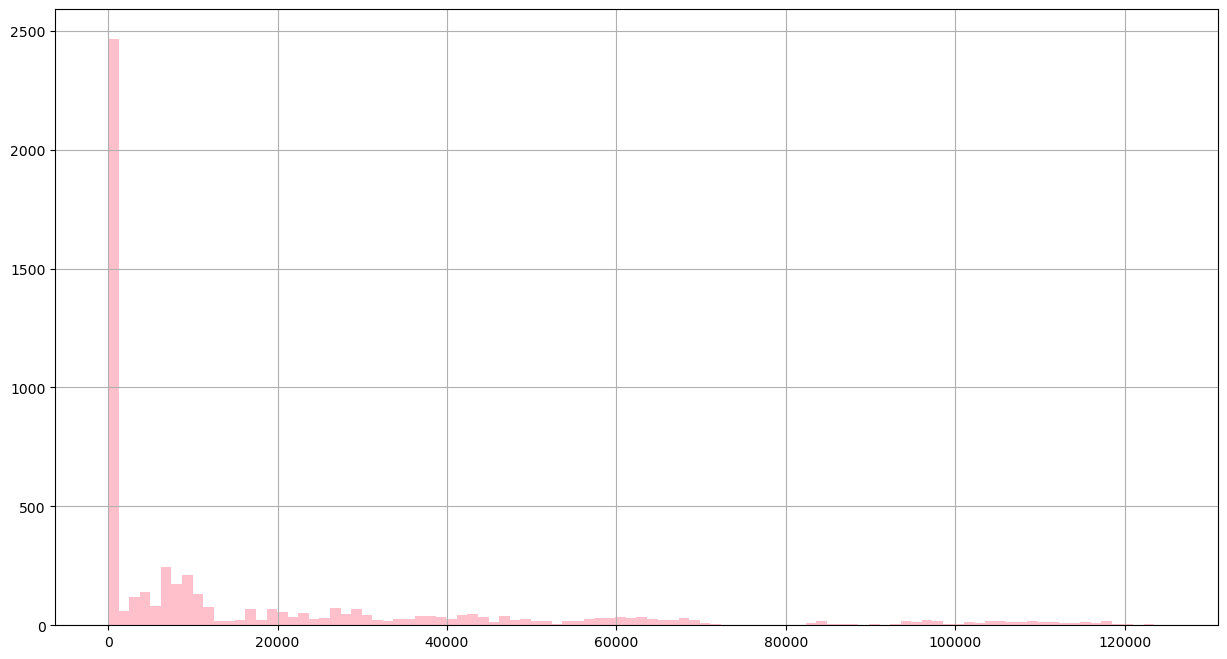

In [ ]:
btc.loc[:, "Close"].hist(bins=100, color='pink')

# Intervalles grandes -> plus de détails mais pas continu
# Intervalles petites -> continuité garantie mais beaucoup moins précis car beuacoup d'informations sont mises au même endroit.

Un autre type de figure pour analyser la distribution, la boite à moustache :

<Axes: >

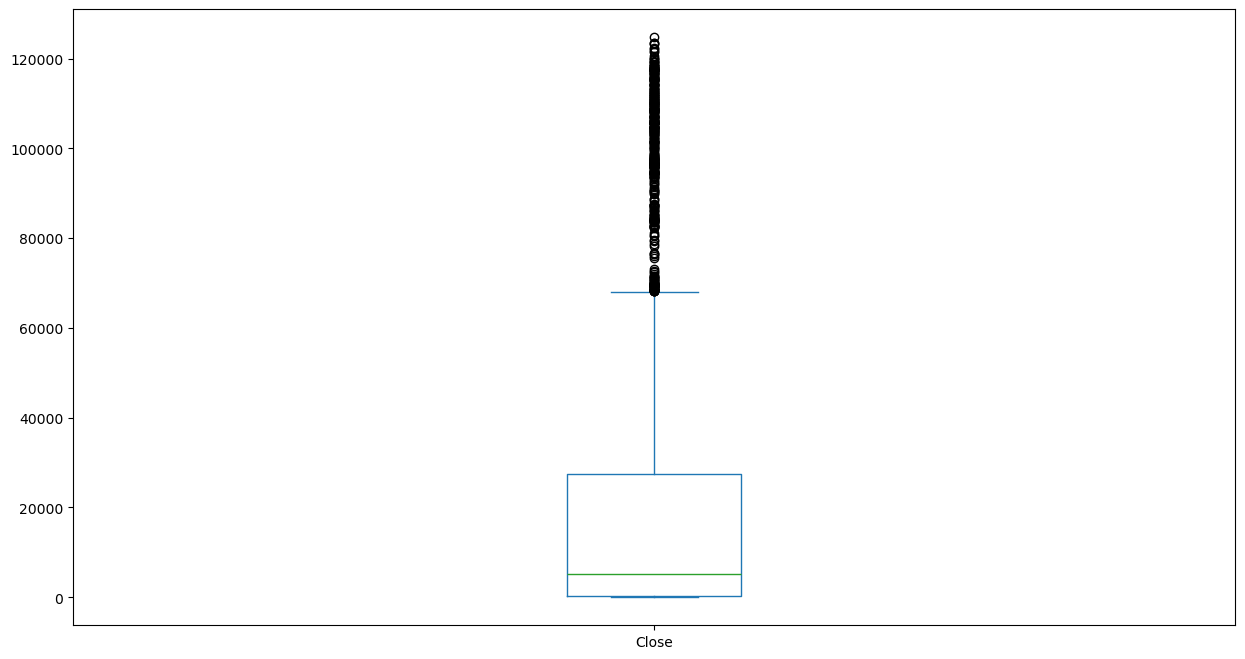

In [18]:
btc.loc[:, 'Close'].plot.box()

Un peu d'explication :
- la distribution représente, pour un intervalle donné, le nombre de valeurs tombants dans cet intervalle
- le 25-percentile représente la valeur à partir de laquelle cette sera supérieure à 25% des autres valeurs
- un 75-percentile représente la valeur à partir de laquelle cette valeur sera supérieure à 75% des autres valeurs
- le rectangle représente les valeurs entre le 25 et 75 percentiles.
- la médiane est donc le 50 percentile
- les ronds noirs sont les données aberrantes, hors normes, par rapport aux restes

Une petite figure Wikipedia sera plus claire :
<center>
<img src="fig/quartile.png" align="center" width="300" height="300">
</center>

Affichons maintenant la distribution via une fonction de densité :

<Axes: ylabel='Density'>

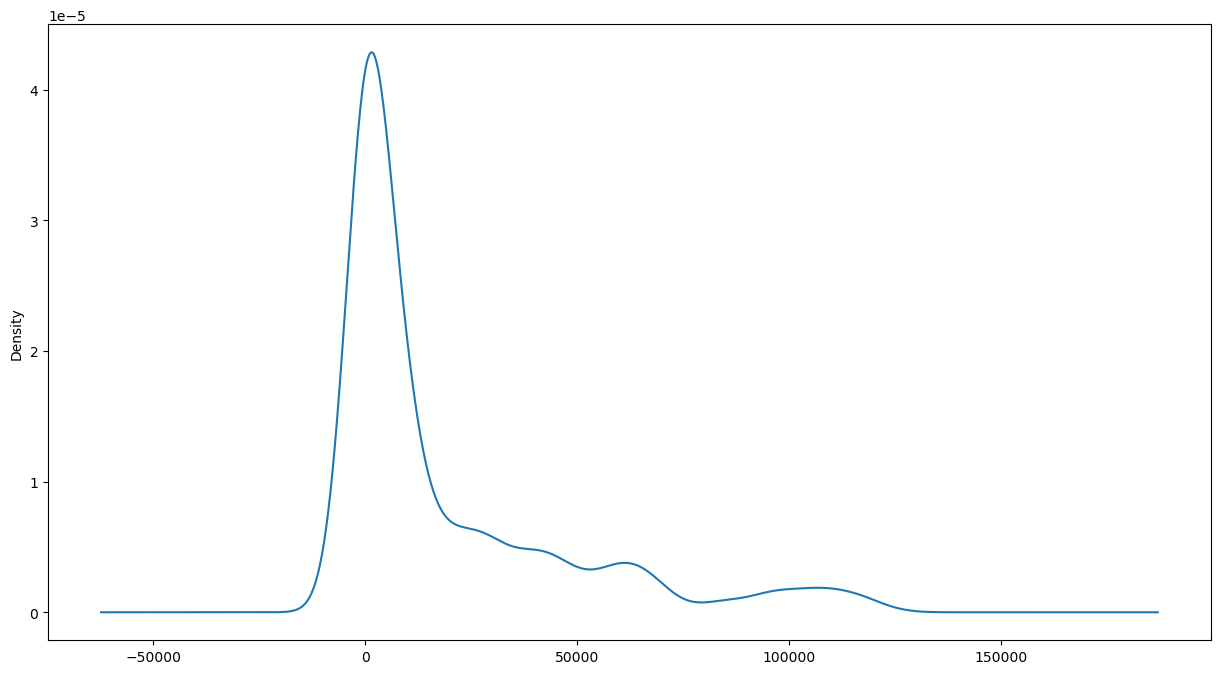

In [19]:
btc.loc[:, 'Close'].plot.density()

On peut résumer les caractéristiques d'une distribution avec deux notions principales :
- la **valeur centrale** : autour de quelle valeur tourne la variable ?
- la **dispersion** : comment les valeurs de la variable sont-elles dispersées autour de la valeur centrale ?

Sur un dataFrame `df`, on peut calculer ces indicateurs de la manière suivante : `df.FONCTION()` ou `df.Variable.FONCTION()`. En guise de FONCTION, vous pouvez utiliser parmi d'autres choix :
- la médiane `median()` ou la moyenne `mean()` pour la valeur centrale,
- l'écart-type `std()` pour la dispersion.

**Questions**:
1. calculer la médiane, la moyenne, la déviation standard de `Close` sur `btc`
2. vérifier que cela est conforme avec la densité obtenue

In [22]:
meanBTC = btc.Close.mean()
medianBTC = btc.Close.median()
stdBTC = btc.Close.std()

print(meanBTC, medianBTC, stdBTC)

18894.74881363969 5258.677411088 28740.854220099747


Pour afficher plusieurs données sur une même figure :

<Axes: xlabel='Date'>

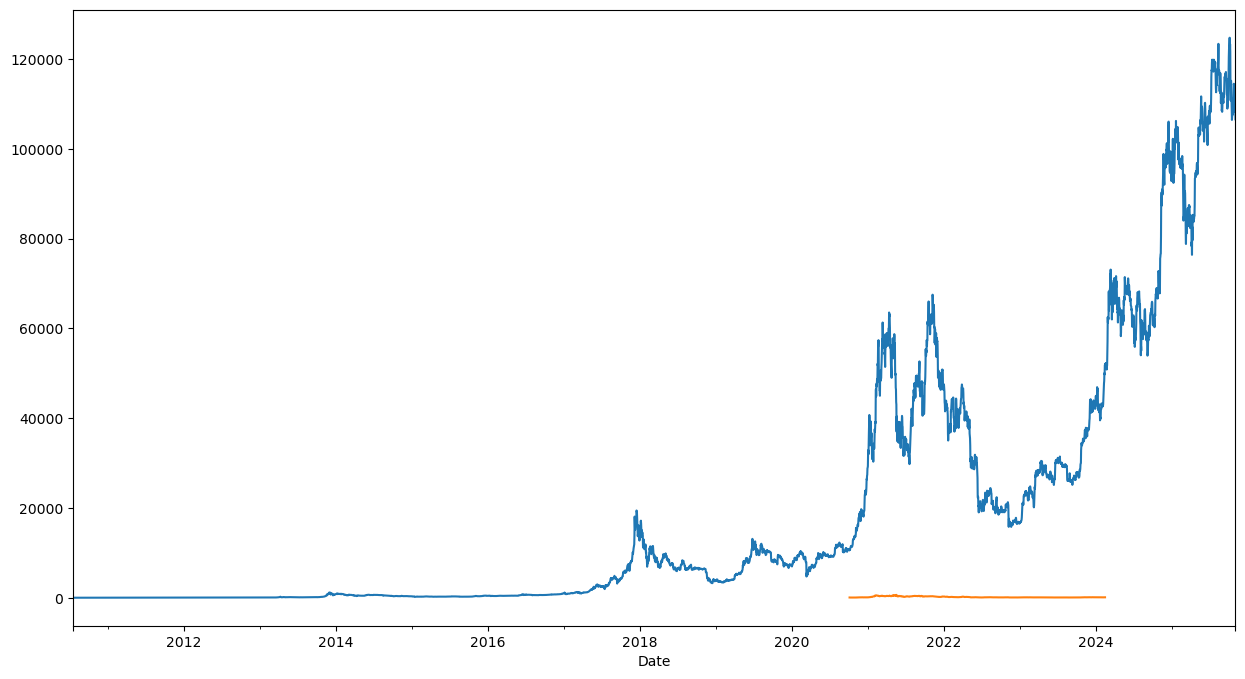

In [25]:
ax = btc.loc[:, "Close"].plot()

ave = loader.get(Loader.COINCODEX, Loader.AAVE)

ave.loc[:, "Close"].plot()

Un peu d'explication :
- un appel à `hist` ou `plot` retourne un objet `Axes` (un peu de doc : `The Axes contains most of the figure elements: Axis, Tick, Line2D, Text, Polygon, etc., and sets the coordinate system.`)
- l'objet `Axes` peut ensuite être passé en paramètre des autres affichages

L'objet `Axes` nous permet ainsi de configurer la légende.

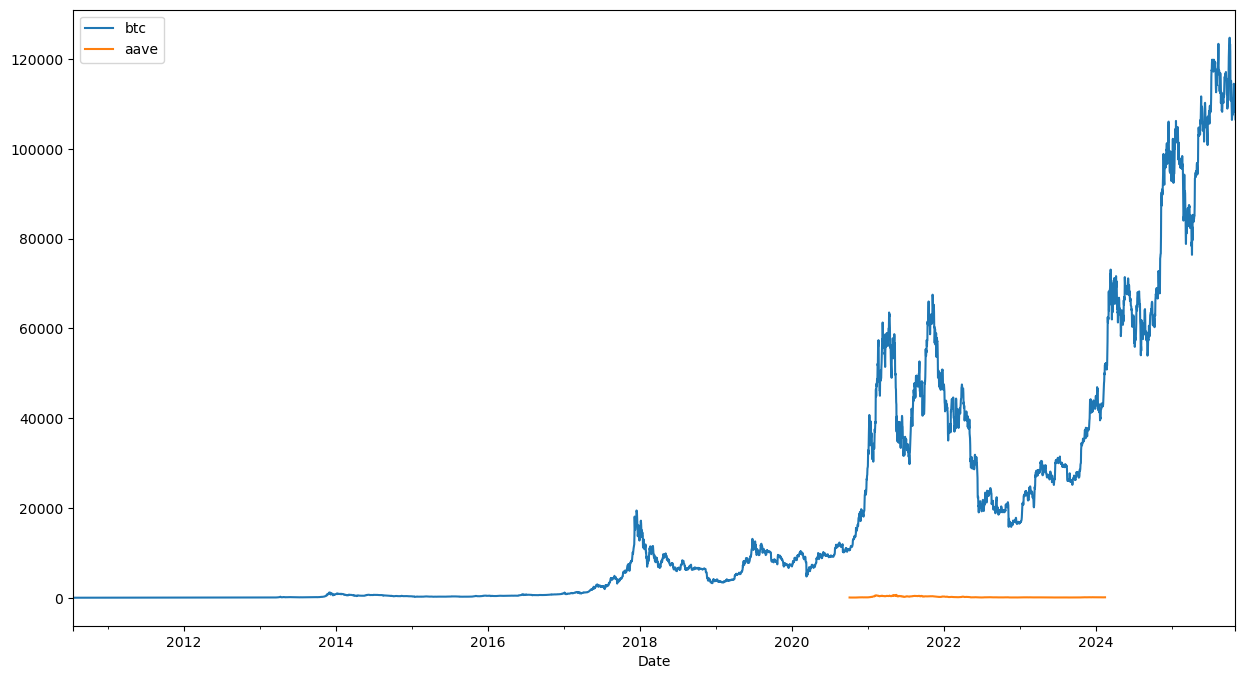

In [27]:
ax = btc.loc[:, "Close"].plot()
ave.loc[:, "Close"].plot(ax = ax)
ax.legend(["btc", "aave"]);



Il est aussi possible d'afficher des nuages de points, par exemple pour vérifier la corrélation entre deux variables :

<Axes: xlabel='Marketcap', ylabel='Volume'>

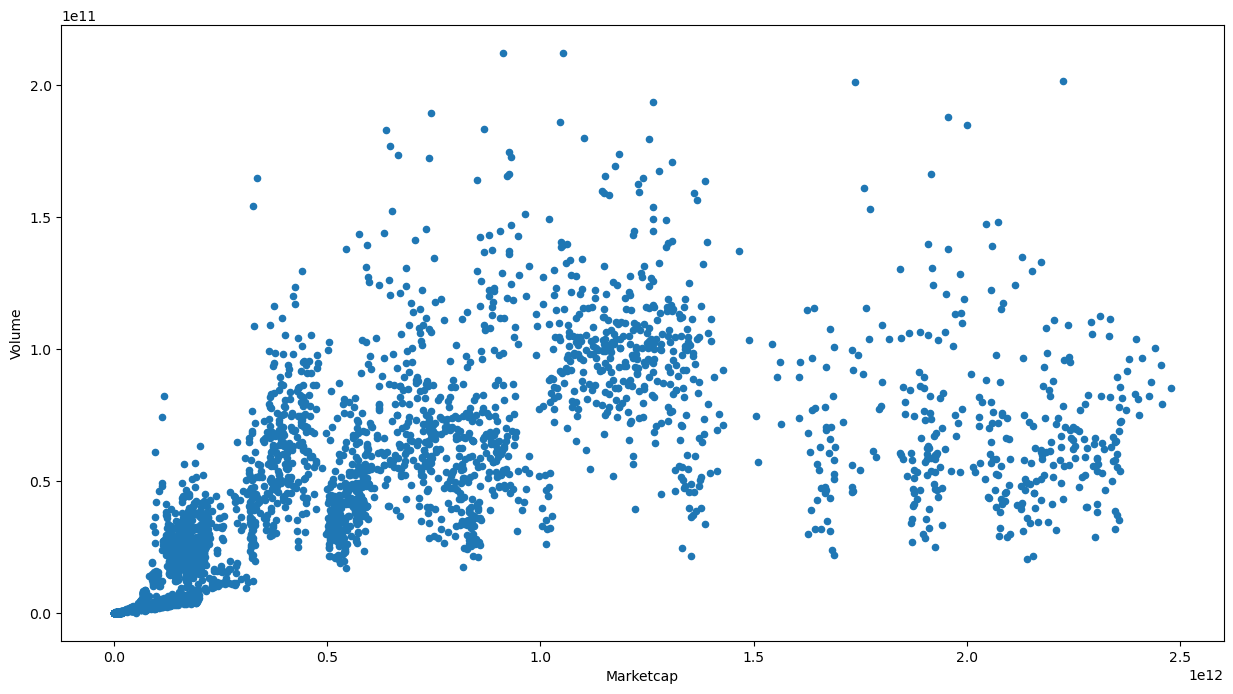

In [28]:
btc.plot.scatter(x='Marketcap', y='Volume')


Etudier la corrélation entre deux variables à du sens : par exemple, il est peut être intéressant d'étudier la corrélation entre le prix du `btc` et celui de l'`ada`. Si une hausse du `btc` implique une hausse du `ada`, et inversement, alors il sera intéressant d'utiliser le `btc` pour prédire l'`ada`.

Réalisons maintenant un peu d'exploration visuelle sur le coins `ada`.

**Questions**:
1. afficher la distribution de `Close`
2. créer une seule figure affichant le `Volume` et `Market Cap` de `ada`, en indiquant la légende 
3. vérifier la corrélation entre le `Volume` et `Market Cap` en calculant la corrélation (indice : cela est faisable en une seule ligne. Un peu de Google pour vous aider, `Pandas Correlation`)
4. Etudier les différences entre les valeurs d'une série temporelle, plutôt que de travailler avec les valeurs, est très fréquent (les variations sont plus stable, et prédire une variation permet aussi de prédire la valeur future). Pour se familiariser avec une telle transformation, créer une figure affichant la différence des valeurs `Close` (différence des prix entre $t$ et $t-1$). `Pandas` a une fonction `diff`, étudier la documentation avant de vous lancer. Procéder par étape, en créant tout d'abord la nouvelle colonne. 


In [ ]:
# Question 1

In [ ]:
# Question 2

In [ ]:
# Question 3

In [ ]:
# Question 4